# Enron classifier runs: recall, average precision, precision, and cost

This notebook reads saved CSV and JSON results only. It makes no API calls. Every row in the main comparison covers the same **559 curated test emails** (73 positive, 486 negative). It verifies source IDs, labels, and email hashes before scoring.

**Average precision (AP)** measures ranking across thresholds and requires a numeric score for each email. JEV supplies its native positive probability; the Gemma probability run uses the normalized log probabilities of the `0` and `1` label tokens. The JSON classifiers saved only labels, so their AP is shown as `—`. A single operating point does not determine AP. Precision and recall use the saved labels at their reported operating points. The Gemma probability run classifies at score ≥ 0.5.

**Label policy:** Gemma's exclude-news run labels relevant third-party news negative. The original benchmark, JEV, and the other Gemma runs include relevant news as positive. Its precision and recall therefore answer a different question. The recovered reasoning run combines 214 historical predictions with 345 new requests; all requests used temperature 0, but only the recovered requests specified seed 2, and one email needed repetition penalty 1.1.

**Cost:** Values are reported OpenRouter charges for the saved run. The recovered reasoning row shows a **known lower bound** for the full experiment: retained historical successes, all recorded recovery attempts (including failures), and one additional 8,192-token pilot success that was not selected for the combined result. Earlier failed or interrupted calls lack complete billing records. These costs describe this test set and request format; the Gemma probability run uses a one-token label prompt, which differs from the JSON prompt.


In [1]:
import csv
import hashlib
import json
from collections import Counter
from pathlib import Path
from IPython.display import Markdown, SVG, display

REPO = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p/'data/jev_test_predictions.csv').exists()), None)
if REPO is None:
    raise FileNotFoundError('Open this notebook from the GTPracticum repository or a child folder')
DATA = REPO/'data'

def read_csv(name):
    with (DATA/name).open(newline='', encoding='utf-8-sig') as f:
        return list(csv.DictReader(f))

def read_json(name):
    return json.loads((DATA/name).read_text())

reference = read_csv('jev_test_predictions.csv')
assert len(reference) == 559
by_id = {int(r['source_row']):r for r in reference}
assert len(by_id) == 559 and set(by_id) == set(range(559))
assert Counter(int(r['label']) for r in reference) == {0:486,1:73}

def checked(rows, name):
    ids = [int(r['source_row']) for r in rows]
    if len(ids) != 559 or len(set(ids)) != 559 or set(ids) != set(by_id):
        raise ValueError(f'{name}: incomplete, duplicate, or different source rows')
    for r in rows:
        old = by_id[int(r['source_row'])]
        if int(r['label']) != int(old['label']) or r['email_sha256'] != old['email_sha256']:
            raise ValueError(f'{name}: label or input hash differs at row {r["source_row"]}')
    return sorted(rows, key=lambda r:int(r['source_row']))

print('Verified reference:',len(reference),'emails;',sum(int(r['label']) for r in reference),'positives.')


Verified reference: 559 emails; 73 positives.


In [2]:
def average_precision(items, score_field):
    """Threshold-average precision, grouping tied scores before each recall step."""
    ordered = sorted(((float(r[score_field]), int(r['label'])) for r in items), reverse=True)
    total_positives = sum(label for _,label in ordered)
    if not total_positives:
        return float('nan')
    tp = fp = 0
    ap = 0.0
    position = 0
    while position < len(ordered):
        score = ordered[position][0]
        if not 0 <= score <= 1:
            raise ValueError('Score outside [0, 1]')
        start = tp
        while position < len(ordered) and ordered[position][0] == score:
            tp += ordered[position][1]
            fp += 1 - ordered[position][1]
            position += 1
        ap += ((tp-start)/total_positives) * (tp/(tp+fp))
    return ap

def metrics(items, score_field=None):
    counts = Counter((int(r['label']),int(r['prediction'])) for r in items)
    tp,fp,fn,tn = counts[1,1],counts[0,1],counts[1,0],counts[0,0]
    if tp+fp+fn+tn != 559:
        raise ValueError('Metrics require all 559 rows')
    return {'TP':tp,'FP':fp,'FN':fn,'TN':tn,
            'precision':tp/(tp+fp) if tp+fp else 0.0,
            'recall':tp/(tp+fn) if tp+fn else 0.0,
            'AP':average_precision(items,score_field) if score_field else None}

runs = [
    ('JEV', 'jev_test_predictions.csv', 'probability', 'Includes news'),
    ('Gemma: exclude news', 'gemma4_exclude_test_predictions.csv', None, 'Excludes news'),
    ('Gemma: include news', 'gemma4_include_test_predictions.csv', None, 'Includes news'),
    ('Gemma: reasoning disabled', 'gemma4_include_no_reasoning_test_predictions.csv', None, 'Includes news'),
    ('Gemma: reasoning recovered', 'gemma4_include_reasoning_recovered_test_predictions.csv', None, 'Includes news'),
    ('Gemma: probability score', 'gemma4_probability_test.csv', 'probability', 'Includes news'),
]
recovery = read_json('gemma4_reasoning_recovery_evaluation.json')
assert recovery['status'] == 'complete' and recovery['rows'] == 559
legacy_cost = sum(float(r['cost'] or 0) for r in read_csv('gemma4_include_reasoning_enabled_test_predictions.csv'))
extra_pilot_cost = sum(float(r['cost'] or 0) for r in read_csv('gemma4_include_reasoning_enabled_8192_test_predictions.csv'))
recovery_known_cost = legacy_cost + recovery['recovery_known_cost_usd'] + extra_pilot_cost

comparison = []
for name, filename, score_field, policy in runs:
    items = checked(read_csv(filename), name)
    if score_field:
        for r in items:
            if int(r['prediction']) != int(float(r[score_field]) >= 0.5):
                raise ValueError(f'{name}: prediction does not match 0.5 threshold')
    result = metrics(items, score_field)
    if name == 'Gemma: reasoning recovered':
        cost, cost_text = recovery_known_cost, f'≥${recovery_known_cost:.5f}'
        assert (result['TP'],result['FP'],result['FN']) == (
            recovery['metrics']['tp'],recovery['metrics']['fp'],recovery['metrics']['fn'])
    else:
        cost = sum(float(r['cost'] or 0) for r in items)
        cost_text = f'${cost:.5f}'
    comparison.append({'name':name,'policy':policy,'cost':cost,'cost_text':cost_text,
                       **result})

header = '| Run | Recall | AP | Precision | Cost for 559 | FP | FN |'
lines = [header, '|---|---:|---:|---:|---:|---:|---:|']
for r in comparison:
    ap = '—' if r['AP'] is None else f"{r['AP']:.3f}"
    lines.append(f"| {r['name']} | {r['recall']:.3f} | {ap} | {r['precision']:.3f} | {r['cost_text']} | {r['FP']} | {r['FN']} |")
display(Markdown('\n'.join(lines)))


| Run | Recall | AP | Precision | Cost for 559 | FP | FN |
|---|---:|---:|---:|---:|---:|---:|
| JEV | 0.699 | 0.772 | 0.680 | $0.01853 | 24 | 22 |
| Gemma: exclude news | 0.260 | — | 0.328 | $0.02259 | 39 | 54 |
| Gemma: include news | 0.918 | — | 0.459 | $0.02261 | 79 | 6 |
| Gemma: reasoning disabled | 0.904 | — | 0.462 | $0.02250 | 77 | 7 |
| Gemma: reasoning recovered | 0.932 | — | 0.479 | ≥$0.09802 | 74 | 5 |
| Gemma: probability score | 0.918 | 0.735 | 0.475 | $0.01358 | 74 | 6 |

## The same results at a glance

The blue bar is recall and the orange bar is precision. The AP column appears only for runs with a score. Costs for recovered reasoning include recorded retry charges; the displayed amount is a lower bound.


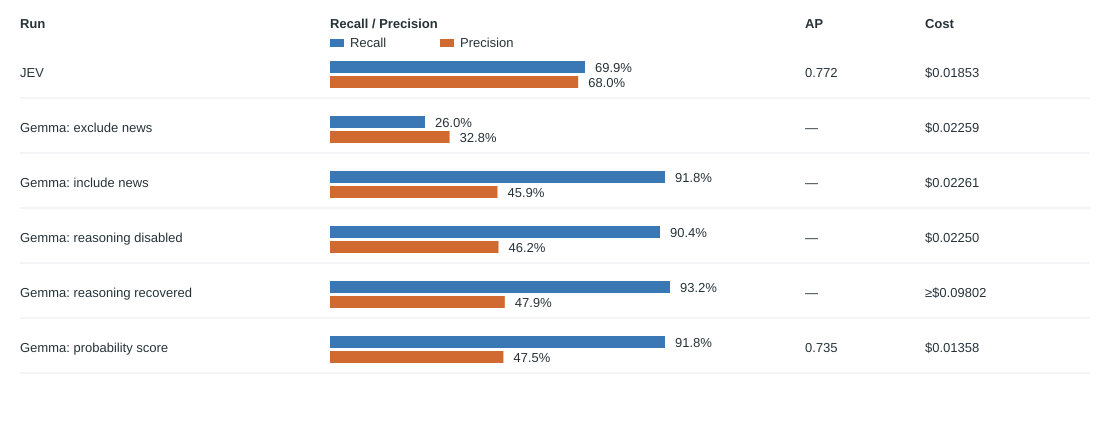

In [3]:
def overview_svg(data):
    height = 95 + len(data)*55
    out = [f'<svg xmlns="http://www.w3.org/2000/svg" width="1120" height="{height}" viewBox="0 0 1120 {height}">',
           '<rect width="100%" height="100%" fill="white"/>',
           '<style>text{font:13px Arial,sans-serif;fill:#263238}.heading{font-weight:bold}</style>',
           '<text x="20" y="28" class="heading">Run</text>',
           '<text x="330" y="28" class="heading">Recall / Precision</text>',
           '<text x="805" y="28" class="heading">AP</text>',
           '<text x="925" y="28" class="heading">Cost</text>',
           '<rect x="330" y="39" width="14" height="8" fill="#3978b4"/>',
           '<text x="350" y="47">Recall</text>',
           '<rect x="440" y="39" width="14" height="8" fill="#d16a31"/>',
           '<text x="460" y="47">Precision</text>']
    for i,r in enumerate(data):
        y = 69+i*55
        out.append(f'<line x1="20" y1="{y+29}" x2="1090" y2="{y+29}" stroke="#e7e9ec"/>')
        out.append(f'<text x="20" y="{y+8}">{r["name"]}</text>')
        for k,color,offset in [('recall','#3978b4',-8),('precision','#d16a31',7)]:
            out.append(f'<rect x="330" y="{y+offset}" width="{365*r[k]:.1f}" height="12" fill="{color}"/>')
            out.append(f'<text x="{340+365*r[k]:.1f}" y="{y+offset+11}">{r[k]:.1%}</text>')
        ap = '—' if r['AP'] is None else f"{r['AP']:.3f}"
        out.append(f'<text x="805" y="{y+8}">{ap}</text>')
        out.append(f'<text x="925" y="{y+8}">{r["cost_text"]}</text>')
    out.append('</svg>')
    return ''.join(out)
display(SVG(overview_svg(comparison)))


## Score calibration and incomplete attempts

The Gemma probability run uses a different one-token prompt from the JSON classifiers. Calibration was fitted on 500 separate validation emails. It changes the 0.5 operating point but makes no additional test-set API calls. Because the calibrators are monotonic, AP remains the same for each model. The threshold below is 0.5 on the calibrated positive-class probability.

Two earlier reasoning-enabled files contain only 214 and 1 saved predictions. Those are the source records for the completed recovered run; they are not scored as separate full-test runs. Their successful-response costs are part of the recovered row's known cost estimate. The estimate excludes older failed or interrupted calls whose costs were not saved.


In [4]:
report = read_json('confidence_comparison/evaluation.json')
calibrated = []
for model, label, filename in [
    ('jev','JEV calibrated','confidence_comparison/jev_test_probabilities.csv'),
    ('gemma4','Gemma score calibrated','confidence_comparison/gemma4_test_probabilities.csv')]:
    scores = read_csv(filename)
    ids = [int(r['source_row']) for r in scores]
    assert len(ids) == 559 and len(set(ids)) == 559 and set(ids) == set(by_id)
    for r in scores:
        old = by_id[int(r['source_row'])]
        assert int(r['label']) == int(old['label'])
    entry = report['models'][model]['calibrated']
    raw_entry = next(r for r in comparison if r['name'] == ('JEV' if model=='jev' else 'Gemma: probability score'))
    assert abs(raw_entry['AP'] - report['models'][model]['raw']['average_precision']) < 1e-12
    assert abs(raw_entry['recall'] - report['models'][model]['raw']['recall']) < 1e-12
    assert abs(raw_entry['precision'] - report['models'][model]['raw']['precision']) < 1e-12
    calibrated.append((label,entry['recall'],raw_entry['AP'],entry['precision'],raw_entry['cost_text']))
lines = ['| Calibrated scores | Recall | AP | Precision | Cost for 559 |',
         '|---|---:|---:|---:|---:|']
for name,recall,ap,precision,cost in calibrated:
    lines.append(f'| {name} | {recall:.3f} | {ap:.3f} | {precision:.3f} | {cost} |')
display(Markdown('\n'.join(lines)))
print('Saved incomplete reasoning files:')
for filename in ['gemma4_include_reasoning_enabled_test_predictions.csv',
                 'gemma4_include_reasoning_enabled_8192_test_predictions.csv']:
    rows = read_csv(filename)
    print(f'{filename}: {len(rows)}/559 saved; successful-response cost ${sum(float(r["cost"] or 0) for r in rows):.5f}')


Saved incomplete reasoning files:
gemma4_include_reasoning_enabled_test_predictions.csv: 214/559 saved; successful-response cost $0.03547
gemma4_include_reasoning_enabled_8192_test_predictions.csv: 1/559 saved; successful-response cost $0.00016


| Calibrated scores | Recall | AP | Precision | Cost for 559 |
|---|---:|---:|---:|---:|
| JEV calibrated | 0.644 | 0.772 | 0.746 | $0.01853 |
| Gemma score calibrated | 0.767 | 0.735 | 0.622 | $0.01358 |

## Reading the comparison

- **Recall first:** the recovered reasoning run retrieves 68/73 positives (93.2%) and produces 74 false positives. The include-news run retrieves 67/73 (91.8%) and produces 79 false positives.
- **Probability ranking:** Gemma retrieves more positives at the 0.5 cutoff, while JEV has higher AP and precision on these labels. The AP values summarize score ordering across thresholds; a single recall/precision pair cannot replace them.
- **Cost:** the one-token Gemma score run is cheapest among complete single-run Gemma workflows. Its prompt and output differ from the JSON runs. The reasoning recovery cost includes recorded failed retries and is a lower bound because earlier failures were not fully tracked.

The source test set has repeated email text and previously inspected labels. Treat these figures as descriptive for this benchmark; use a fresh labeled set for a confirmatory comparison.


## Recall and specificity: what the tradeoff means

The table and analysis below use the original 559 curated labels for every complete run. Specificity is `TN / (TN + FP)`; higher specificity means fewer negative emails are sent for review.


In [5]:
by_name = {r['name']:r for r in comparison}
assert all(r['TP'] + r['FN'] == 73 and r['TN'] + r['FP'] == 486 for r in comparison)

def specificity(row):
    return row['TN'] / (row['TN'] + row['FP'])

lines = ['| Run | Recall (found / 73) | Specificity (rejected / 486) | Missed positives | False alarms |',
         '|---|---:|---:|---:|---:|']
for r in comparison:
    lines.append(f"| {r['name']} | {r['recall']:.1%} ({r['TP']}/73) | {specificity(r):.1%} ({r['TN']}/486) | {r['FN']} | {r['FP']} |")
display(Markdown('\n'.join(lines)))

recovered = by_name['Gemma: reasoning recovered']
jev = by_name['JEV']
raw_gemma = by_name['Gemma: probability score']
calibrated_gemma = report['models']['gemma4']['calibrated']
calibrated_jev = report['models']['jev']['calibrated']
analysis = f'''**Recall** is the share of 73 positive emails found. **Specificity** is the share of 486 negative emails correctly rejected. Their complements are missed positives and false alarms, respectively.

- **For recall-first review:** the recovered reasoning workflow found {recovered['TP']}/73 positives ({recovered['recall']:.1%}) and correctly rejected {recovered['TN']}/486 negatives ({specificity(recovered):.1%}). The include-news workflow found {by_name['Gemma: include news']['TP']}/73 positives ({by_name['Gemma: include news']['recall']:.1%}) and rejected {by_name['Gemma: include news']['TN']}/486 negatives ({specificity(by_name['Gemma: include news']):.1%}).
- **For fewer false alarms:** JEV rejected {jev['TN']}/486 negatives ({specificity(jev):.1%}) but found {jev['TP']}/73 positives ({jev['recall']:.1%}). Relative to recovered Gemma, it avoided {recovered['FP']-jev['FP']} false alarms and missed {jev['FN']-recovered['FN']} more positives.
- **Threshold choice matters:** on the one-token Gemma score run, calibration moved the 0.5 cutoff from {raw_gemma['recall']:.1%} recall / {specificity(raw_gemma):.1%} specificity to {calibrated_gemma['recall']:.1%} recall / {calibrated_gemma['tn']/(calibrated_gemma['tn']+calibrated_gemma['fp']):.1%} specificity. JEV's calibrated cutoff gave {calibrated_jev['recall']:.1%} recall / {calibrated_jev['tn']/(calibrated_jev['tn']+calibrated_jev['fp']):.1%} specificity. Those are new operating points on the same saved scores; select a cutoff on validation data for the review workload.

The exclude-news Gemma run uses a different positive rule. Its low recall on the original labels largely reflects that rule, so it should not be used as a model-only comparison. The recovered reasoning workflow combines settings across rows, and these test emails have already been inspected in earlier analyses.
'''
display(Markdown(analysis))


| Run | Recall (found / 73) | Specificity (rejected / 486) | Missed positives | False alarms |
|---|---:|---:|---:|---:|
| JEV | 69.9% (51/73) | 95.1% (462/486) | 22 | 24 |
| Gemma: exclude news | 26.0% (19/73) | 92.0% (447/486) | 54 | 39 |
| Gemma: include news | 91.8% (67/73) | 83.7% (407/486) | 6 | 79 |
| Gemma: reasoning disabled | 90.4% (66/73) | 84.2% (409/486) | 7 | 77 |
| Gemma: reasoning recovered | 93.2% (68/73) | 84.8% (412/486) | 5 | 74 |
| Gemma: probability score | 91.8% (67/73) | 84.8% (412/486) | 6 | 74 |

**Recall** is the share of 73 positive emails found. **Specificity** is the share of 486 negative emails correctly rejected. Their complements are missed positives and false alarms, respectively.

- **For recall-first review:** the recovered reasoning workflow found 68/73 positives (93.2%) and correctly rejected 412/486 negatives (84.8%). The include-news workflow found 67/73 positives (91.8%) and rejected 407/486 negatives (83.7%).
- **For fewer false alarms:** JEV rejected 462/486 negatives (95.1%) but found 51/73 positives (69.9%). Relative to recovered Gemma, it avoided 50 false alarms and missed 17 more positives.
- **Threshold choice matters:** on the one-token Gemma score run, calibration moved the 0.5 cutoff from 91.8% recall / 84.8% specificity to 76.7% recall / 93.0% specificity. JEV's calibrated cutoff gave 64.4% recall / 96.7% specificity. Those are new operating points on the same saved scores; select a cutoff on validation data for the review workload.

The exclude-news Gemma run uses a different positive rule. Its low recall on the original labels largely reflects that rule, so it should not be used as a model-only comparison. The recovered reasoning workflow combines settings across rows, and these test emails have already been inspected in earlier analyses.
